# Setup

In [19]:
import os, re, gc, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# data loading

In [47]:
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

DATA_DIR = r"C:\Users\Admin\OneDrive\Desktop\New folder"          # <-- folder containing the unzipped CSV files
RANDOM_STATE = 42

required = ['application_train', 'bureau', 'bureau_balance', 'previous_application',
            'POS_CASH_balance', 'credit_card_balance', 'installments_payments']
missing_files = [f for f in required if not os.path.exists(f'{DATA_DIR}/{f}.csv')]
assert not missing_files, f'Missing files in {DATA_DIR!r}: {missing_files}'

def reduce_mem(df):
    """Downcast numeric columns to cut memory roughly in half."""
    for c in df.select_dtypes('float64').columns:
        df[c] = df[c].astype('float32')
    for c in df.select_dtypes('int64').columns:
        df[c] = pd.to_numeric(df[c], downcast='integer')
    return df

app = reduce_mem(pd.read_csv(f'{DATA_DIR}/application_train.csv'))
print('application_train:', app.shape)
display(app.head())

application_train: (6000, 24)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,OCCUPATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,CNT_FAM_MEMBERS,ORGANIZATION_TYPE,OWN_CAR_AGE
0,100000,0,Revolving loans,F,Y,Y,0,"151,062.6562","839,880.2500","26,158.1328","327,748.9062",Pensioner,Lower secondary,Widow,With parents,-18906,-7715,NaN,0.6497,0.4296,0.5404,3,XNA,12.0000
1,100001,0,Cash loans,M,N,N,1,"232,252.8750","464,343.5312","31,203.3184","535,785.9375",State servant,Secondary,Married,With parents,-24861,-5408,Core staff,0.8273,0.8065,NaN,4,Business Entity,19.0000
2,100002,0,Cash loans,F,Y,Y,3,"92,488.1641","868,547.8750","26,165.5391","330,623.6250",Working,Secondary,Married,With parents,-15475,365243,Core staff,NaN,0.7650,0.8387,4,Self-employed,9.0000
3,100003,0,Revolving loans,M,Y,Y,2,"387,169.3125","478,847.6250","42,962.6914","495,457.0312",Pensioner,Higher education,Married,With parents,-23734,-2423,Core staff,NaN,0.0381,0.5661,4,Self-employed,11.0000
4,100004,0,Revolving loans,M,N,N,0,"87,476.4297","1,460,748.3750","24,823.0273","1,330,985.7500",Commercial associate,Higher education,Married,With parents,-11468,-4348,NaN,0.9141,0.7634,0.2899,5,XNA,14.0000


In [88]:
data                  = pd.read_csv("application_train.csv")
bureau                = pd.read_csv("bureau.csv")
bureau_balance        = pd.read_csv("bureau_balance.csv")
credit_card_balance   = pd.read_csv("credit_card_balance.csv")
installments_payments = pd.read_csv("installments_payments.csv")
pos_cash_balance      = pd.read_csv("POS_CASH_balance.csv")
previous_application  = pd.read_csv("previous_application.csv")

In [89]:
print ("application_train     :",data.shape)
print ("bureau                :",bureau.shape)
print ("bureau_balance        :",bureau_balance.shape)
print ("credit_card_balance   :",credit_card_balance.shape)
print ("installments_payments :",installments_payments.shape)
print ("pos_cash_balance      :",pos_cash_balance.shape)
print ("previous_application  :",previous_application.shape)

application_train     : (6000, 24)
bureau                : (15000, 9)
bureau_balance        : (60000, 3)
credit_card_balance   : (8000, 7)
installments_payments : (50000, 6)
pos_cash_balance      : (40000, 6)
previous_application  : (14000, 9)


#  Data Analysis Report (EDA)

### Structure and data types

In [48]:
print(app.dtypes.value_counts())
print('\nMemory: %.1f MB' % (app.memory_usage(deep=True).sum() / 1e6))
display(app.describe().T.head(25))

str        10
float32     8
int8        3
int32       2
int16       1
Name: count, dtype: int64

Memory: 1.2 MB


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,"6,000.0000","102,999.5000","1,732.1951","100,000.0000","101,499.7500","102,999.5000","104,499.2500","105,999.0000"
TARGET,"6,000.0000",0.0300,0.1706,0.0000,0.0000,0.0000,0.0000,1.0000
CNT_CHILDREN,"6,000.0000",1.4883,1.1176,0.0000,0.0000,1.0000,2.0000,3.0000
AMT_INCOME_TOTAL,"6,000.0000","182,987.2656","99,217.1797","27,132.4648","115,656.3750","161,212.8828","223,649.5273","1,009,378.6250"
AMT_CREDIT,"6,000.0000","528,596.3750","352,069.5625","41,394.4258","293,816.8594","437,437.0625","662,176.0781","4,045,465.5000"
AMT_ANNUITY,"6,000.0000","24,943.1953","13,389.8779","3,260.4177","15,814.8555","21,957.5879","30,685.5083","174,968.9375"
AMT_GOODS_PRICE,"6,000.0000","527,035.9375","349,050.8125","47,064.6953","292,667.9062","441,983.3438","662,658.5938","4,765,294.5000"
DAYS_BIRTH,"6,000.0000","-16,245.4775","5,067.5232","-24,999.0000","-20,606.7500","-16,125.5000","-11,987.7500","-7,506.0000"
DAYS_EMPLOYED,"6,000.0000","61,809.7947","143,412.3205","-11,990.0000","-8,086.0000","-4,659.0000","-1,000.2500","365,243.0000"
EXT_SOURCE_1,"5,373.0000",0.4992,0.2896,0.0001,0.2507,0.4949,0.7483,1.0000


### Target distribution (class imbalance)

TARGET
0    5820
1     180

Default rate: 3.00%   |   imbalance ratio 1 : 32.3


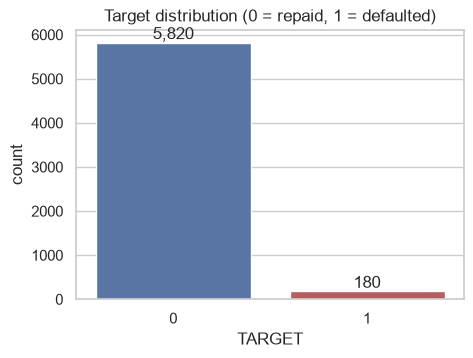

In [49]:
vc = app['TARGET'].value_counts()
print(vc.to_string())
print('\nDefault rate: %.2f%%   |   imbalance ratio 1 : %.1f' % (app['TARGET'].mean()*100, vc[0]/vc[1]))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x='TARGET', data=app, ax=ax, palette=['#4C72B0', '#C44E52'])
ax.set_title('Target distribution (0 = repaid, 1 = defaulted)')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.show()

### Missing values and data-quality checks

4 of 24 columns contain missing values; 0 have > 50% missing.


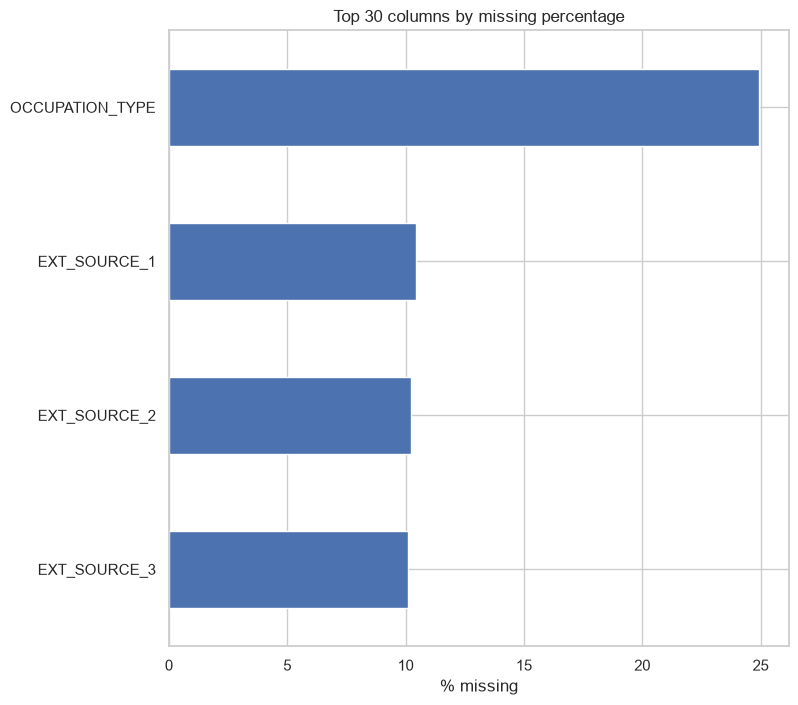

In [50]:
miss = (app.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
print(f'{len(miss)} of {app.shape[1]} columns contain missing values; {(miss > 50).sum()} have > 50% missing.')

fig, ax = plt.subplots(figsize=(8, 8))
miss.head(30).sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('% missing'); ax.set_title('Top 30 columns by missing percentage')
plt.show()

In [51]:
print('Duplicate SK_ID_CURR           :', app['SK_ID_CURR'].duplicated().sum())
print('DAYS_EMPLOYED == 365243 (sentinel):', (app['DAYS_EMPLOYED'] == 365243).sum())
print('CODE_GENDER values             :', app['CODE_GENDER'].value_counts().to_dict())
print('ORGANIZATION_TYPE == XNA       :', (app['ORGANIZATION_TYPE'] == 'XNA').sum())

anom = app['DAYS_EMPLOYED'] == 365243
print('\nDefault rate - sentinel group : %.2f%%' % (app.loc[anom, 'TARGET'].mean()*100))
print('Default rate - normal group   : %.2f%%' % (app.loc[~anom, 'TARGET'].mean()*100))

Duplicate SK_ID_CURR           : 0
DAYS_EMPLOYED == 365243 (sentinel): 1095
CODE_GENDER values             : {'F': 3897, 'M': 2091, 'XNA': 12}
ORGANIZATION_TYPE == XNA       : 1879

Default rate - sentinel group : 1.83%
Default rate - normal group   : 3.26%


### Univariate analysis: numeric features

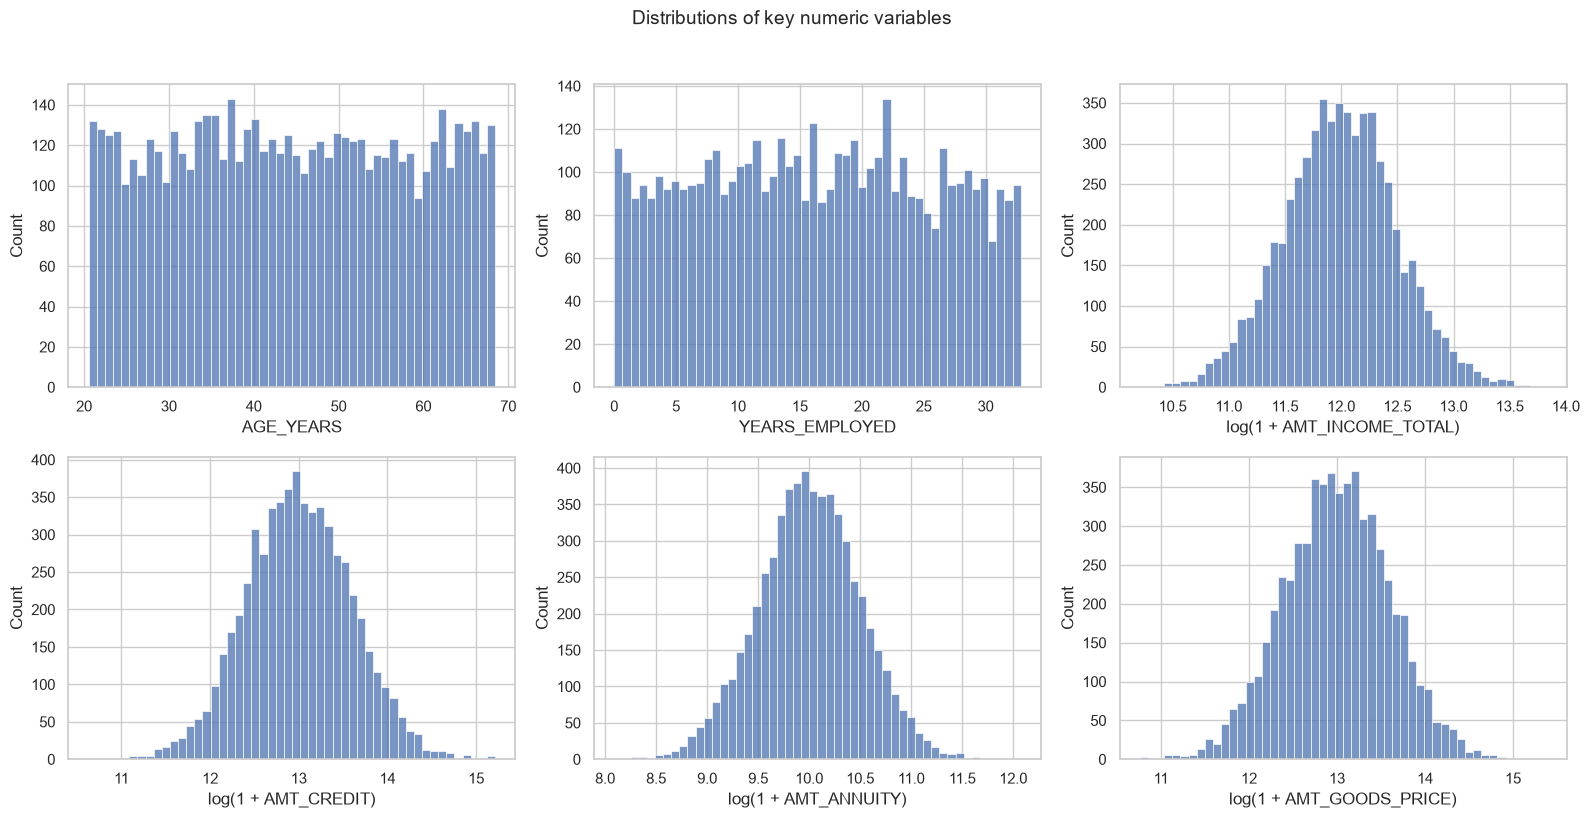

In [53]:
tmp = app.copy()
tmp['AGE_YEARS'] = -tmp['DAYS_BIRTH'] / 365.25
tmp['YEARS_EMPLOYED'] = -tmp['DAYS_EMPLOYED'].replace(365243, np.nan) / 365.25

cols = ['AGE_YEARS', 'YEARS_EMPLOYED', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cols):
    d = tmp[c].dropna()
    if c.startswith('AMT'):
        d = np.log1p(d); ax.set_xlabel(f'log(1 + {c})')
    else:
        ax.set_xlabel(c)
    sns.histplot(d, bins=50, ax=ax, color='#4C72B0')
fig.suptitle('Distributions of key numeric variables', y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

### Numeric features vs. target

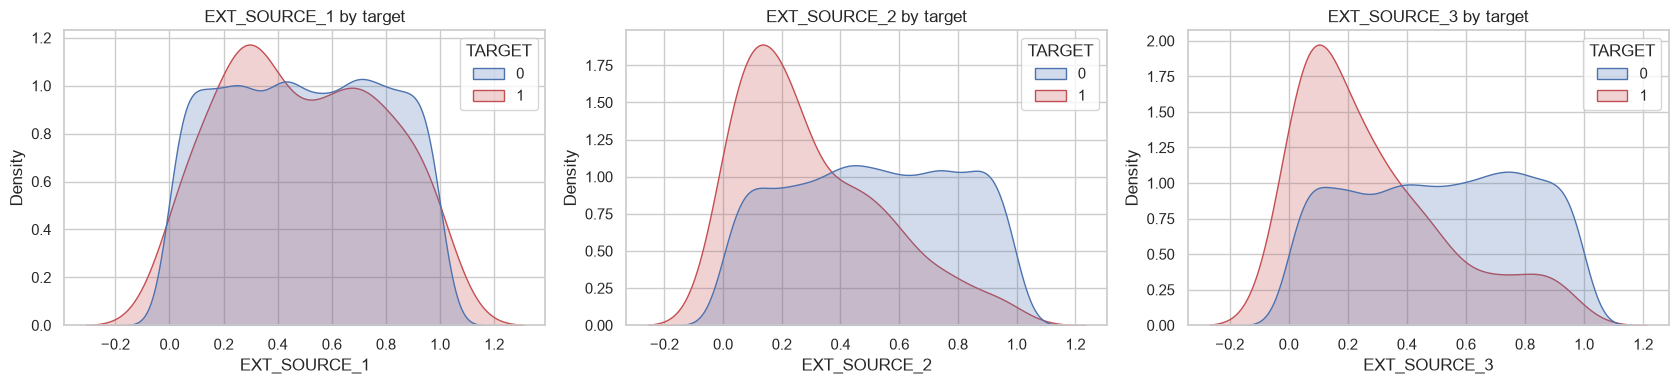

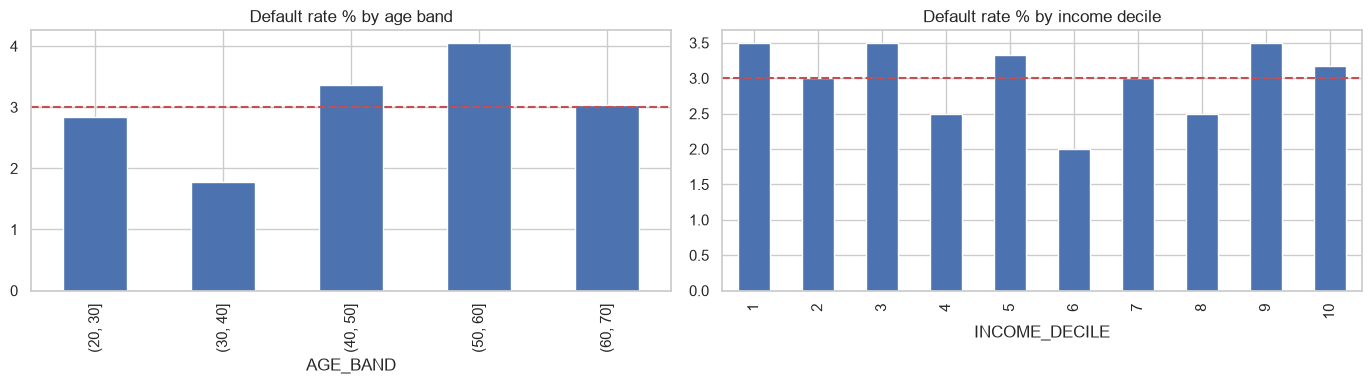

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    sns.kdeplot(data=app, x=c, hue='TARGET', common_norm=False, fill=True, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(f'{c} by target')
plt.tight_layout(); plt.show()

tmp['AGE_BAND'] = pd.cut(tmp['AGE_YEARS'], [20, 30, 40, 50, 60, 70])
tmp['INCOME_DECILE'] = pd.qcut(tmp['AMT_INCOME_TOTAL'], 10, labels=False, duplicates='drop') + 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tmp.groupby('AGE_BAND')['TARGET'].mean().mul(100).plot.bar(ax=axes[0], color='#4C72B0', title='Default rate % by age band')
tmp.groupby('INCOME_DECILE')['TARGET'].mean().mul(100).plot.bar(ax=axes[1], color='#4C72B0', title='Default rate % by income decile')
for a in axes: a.axhline(app['TARGET'].mean()*100, color='r', ls='--')
plt.tight_layout(); plt.show()

### Categorical features vs. target (default rate by category)

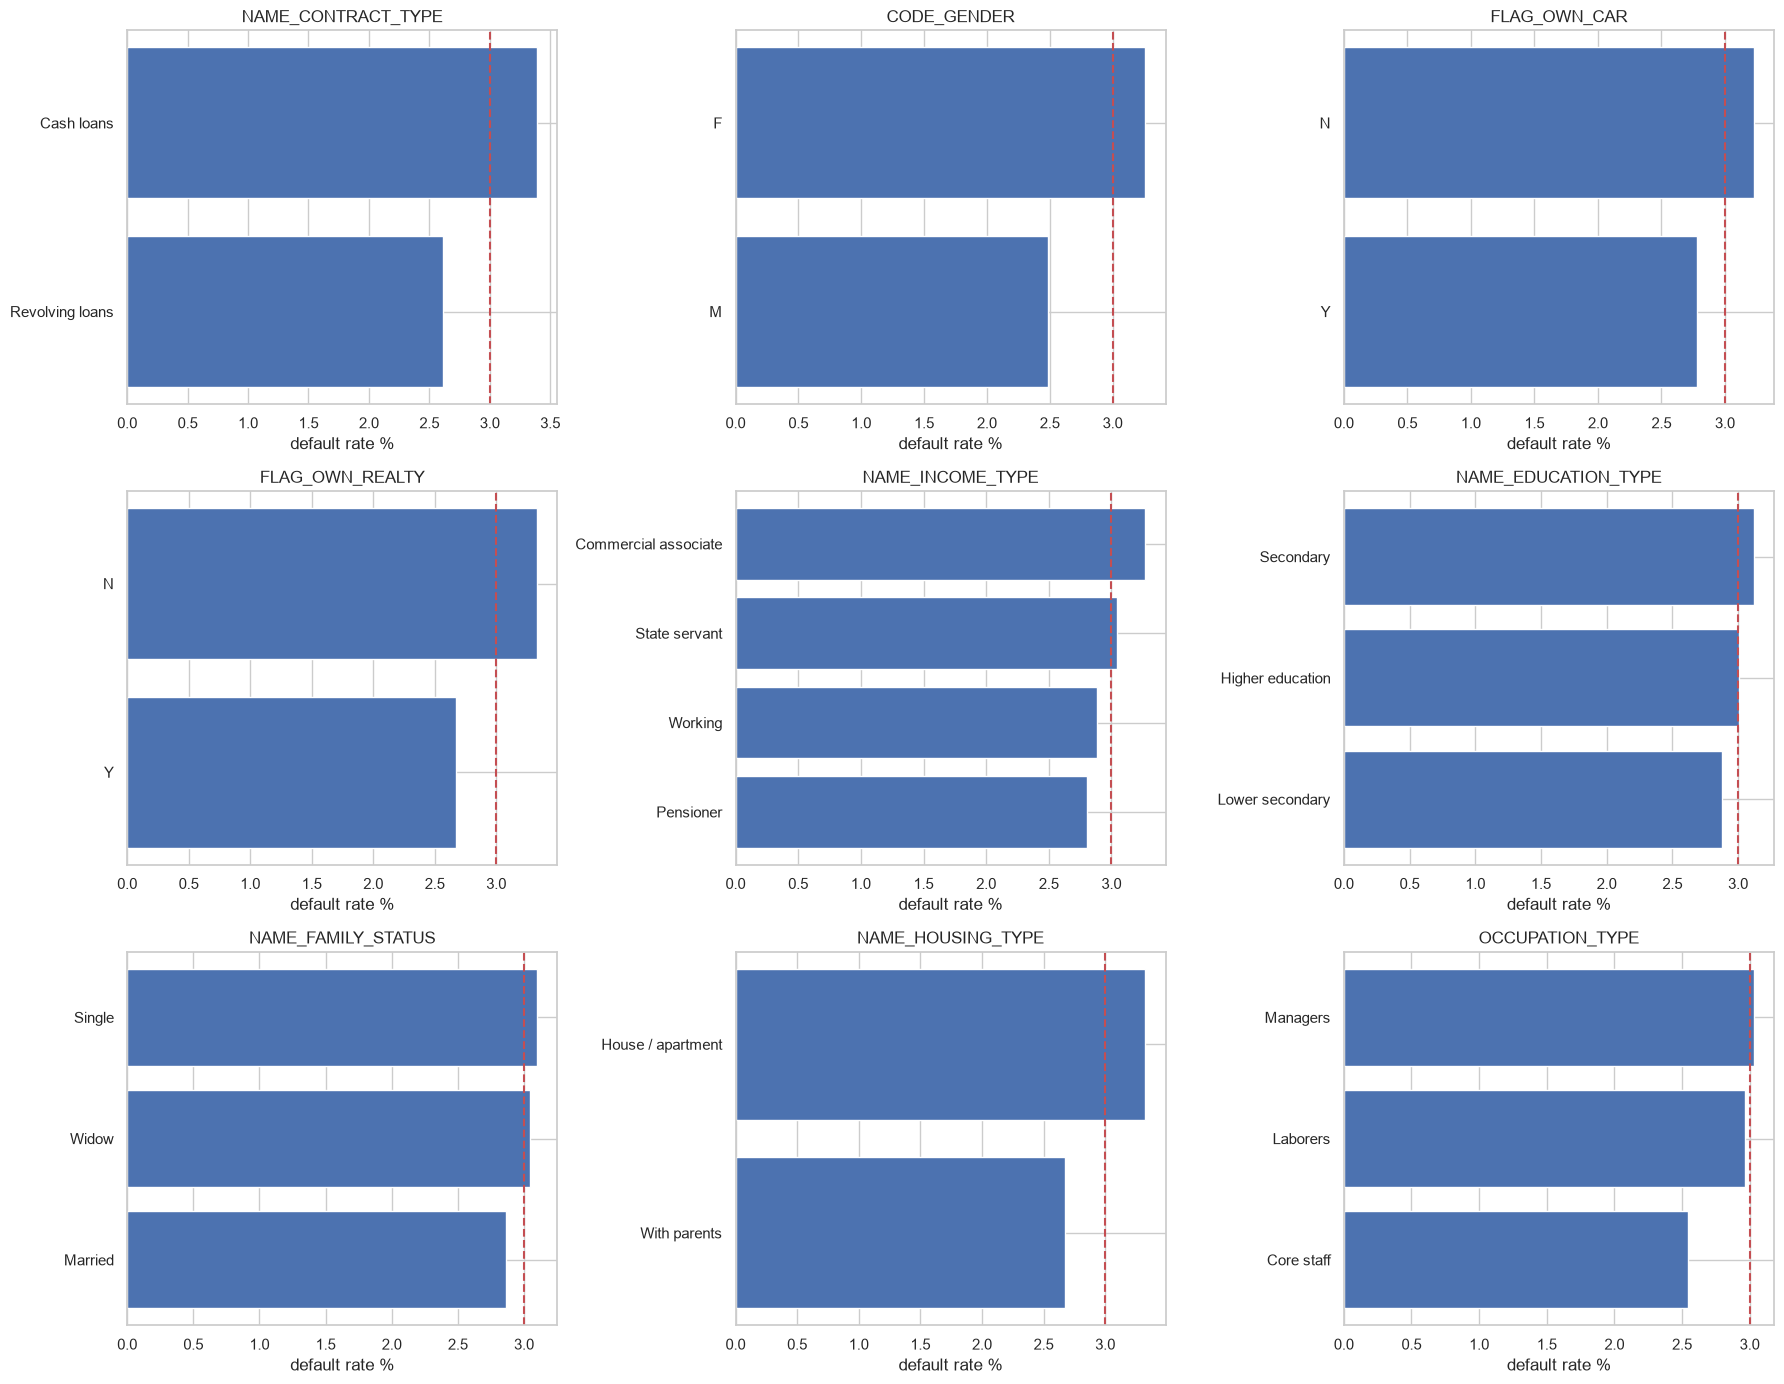

In [55]:
cat_cols = [c for c in ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
                        'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                        'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE'] if c in app.columns]
base = app['TARGET'].mean() * 100
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, c in zip(axes.ravel(), cat_cols):
    r = app.groupby(c)['TARGET'].agg(['mean', 'size'])
    r = r[r['size'] >= 100].sort_values('mean')
    ax.barh(r.index.astype(str), r['mean'] * 100, color='#4C72B0')
    ax.axvline(base, color='r', ls='--'); ax.set_title(c); ax.set_xlabel('default rate %')
for ax in axes.ravel()[len(cat_cols):]: ax.axis('off')
plt.tight_layout(); plt.show()

### Correlation analysis

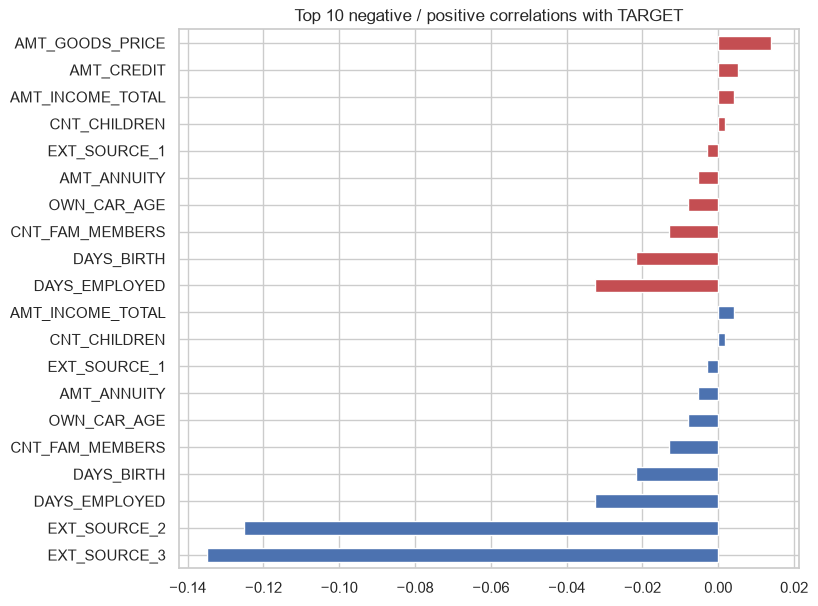

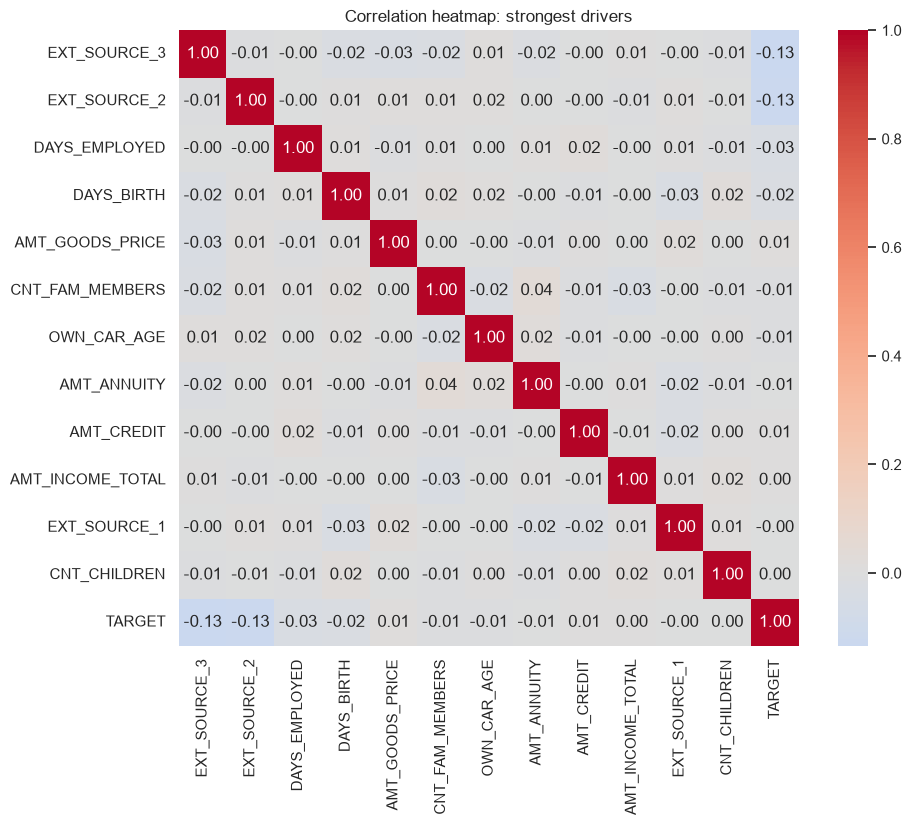

In [57]:
num = app.select_dtypes('number').drop(columns=['SK_ID_CURR'])
corr = num.corr()['TARGET'].drop('TARGET').dropna().sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
pd.concat([corr.head(10), corr.tail(10)]).plot.barh(ax=ax, color=['#4C72B0']*10 + ['#C44E52']*10)
ax.set_title('Top 10 negative / positive correlations with TARGET'); plt.show()

top = corr.abs().sort_values(ascending=False).head(12).index.tolist() + ['TARGET']
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num[top].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation heatmap: strongest drivers'); plt.show()

### Auxiliary tables overview

In [58]:
aux = ['bureau', 'bureau_balance', 'previous_application', 'POS_CASH_balance',
       'credit_card_balance', 'installments_payments']
rows = []
for f in aux:
    head = pd.read_csv(f'{DATA_DIR}/{f}.csv', nrows=1000)
    rows.append({'table': f, 'columns': head.shape[1], 'keys': ', '.join(c for c in head.columns if c.startswith('SK_ID')),
                 'sample columns': ', '.join(head.columns[:6]) + ' ...'})
display(pd.DataFrame(rows))

,table,columns,keys,sample columns
0,bureau,9,"SK_ID_CURR, SK_ID_BUREAU","SK_ID_CURR, SK_ID_BUREAU, CREDIT_ACTIVE, DAYS_..."
1,bureau_balance,3,SK_ID_BUREAU,"SK_ID_BUREAU, MONTHS_BALANCE, STATUS ..."
2,previous_application,9,"SK_ID_PREV, SK_ID_CURR","SK_ID_PREV, SK_ID_CURR, NAME_CONTRACT_STATUS, ..."
3,POS_CASH_balance,6,"SK_ID_PREV, SK_ID_CURR","SK_ID_PREV, SK_ID_CURR, MONTHS_BALANCE, SK_DPD..."
4,credit_card_balance,7,"SK_ID_PREV, SK_ID_CURR","SK_ID_PREV, SK_ID_CURR, MONTHS_BALANCE, AMT_BA..."
5,installments_payments,6,"SK_ID_PREV, SK_ID_CURR","SK_ID_PREV, SK_ID_CURR, DAYS_INSTALMENT, DAYS_..."


# Feature engineering

* application_train has one row per loan. Every other table has many rows per client, so we aggregate each table to one row per SK_ID_CURR and left-join it.


In [59]:
def agg_numeric(df, key, prefix, ignore=('SK_ID_PREV', 'SK_ID_BUREAU', 'SK_ID_CURR'), funcs=('mean', 'max', 'min', 'sum')):
    """Aggregate every numeric column of df by `key` and return a frame indexed by key."""
    drop = [c for c in ignore if c in df.columns and c != key]
    num = df.select_dtypes('number').drop(columns=drop)
    out = num.groupby(key).agg(list(funcs))
    out.columns = [f'{prefix}_{c}_{s}'.upper() for c, s in out.columns]
    return out.astype('float32')

def clean_days(df):
    """365243 is a placeholder meaning 'not applicable' in every DAYS_* column."""
    for c in df.columns:
        if c.startswith('DAYS_'):
            df[c] = df[c].replace(365243, np.nan)
    return df

### Application table: cleaning and domain features

In [60]:
def prep_application(df):
    df = df.copy()
    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype('int8')
    df = clean_days(df)
    df['CODE_GENDER'] = df['CODE_GENDER'].replace('XNA', np.nan)
    df['ORGANIZATION_TYPE'] = df['ORGANIZATION_TYPE'].replace('XNA', np.nan)
    df['AMT_INCOME_TOTAL'] = df['AMT_INCOME_TOTAL'].clip(upper=df['AMT_INCOME_TOTAL'].quantile(0.999))  # winsorise extreme incomes

    df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25
    df['YEARS_EMPLOYED'] = -df['DAYS_EMPLOYED'] / 365.25
    df['EMPLOYED_TO_AGE'] = df['YEARS_EMPLOYED'] / df['AGE_YEARS']
    df['CREDIT_TO_INCOME'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
    df['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['CREDIT_TERM'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['CREDIT_TO_GOODS'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
    ext = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in df.columns]
    df['EXT_SOURCE_MEAN'] = df[ext].mean(axis=1)
    df['EXT_SOURCE_PROD'] = df[ext].prod(axis=1, skipna=False)
    df['EXT_SOURCE_STD'] = df[ext].std(axis=1)
    return df.replace([np.inf, -np.inf], np.nan)

app_fe = prep_application(app)
print('Application features:', app_fe.shape)

Application features: (6000, 36)


### Bureau and bureau_balance (credits from other institutions)

In [61]:
status_map = {'C': 0, 'X': 0, '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5}
parts = []
for ch in pd.read_csv(f'{DATA_DIR}/bureau_balance.csv', chunksize=2_000_000):   # chunked: ~27M rows
    ch['S'] = ch['STATUS'].astype(str).map(status_map).astype('float32')
    ch['LATE'] = (ch['S'] > 0).astype('int8')
    parts.append(ch.groupby('SK_ID_BUREAU').agg(BB_COUNT=('S', 'size'), BB_LATE_SUM=('LATE', 'sum'),
                                                BB_STATUS_MAX=('S', 'max'), BB_MONTHS_MIN=('MONTHS_BALANCE', 'min')))
bb = pd.concat(parts).groupby(level=0).agg({'BB_COUNT': 'sum', 'BB_LATE_SUM': 'sum', 'BB_STATUS_MAX': 'max', 'BB_MONTHS_MIN': 'min'})
bb['BB_LATE_RATIO'] = bb['BB_LATE_SUM'] / bb['BB_COUNT']
del parts; gc.collect()

bureau = reduce_mem(pd.read_csv(f'{DATA_DIR}/bureau.csv'))
bureau = clean_days(bureau).merge(bb, left_on='SK_ID_BUREAU', right_index=True, how='left')

act = pd.get_dummies(bureau['CREDIT_ACTIVE'], prefix='ACT').astype('int8')
act['SK_ID_CURR'] = bureau['SK_ID_CURR']
bureau_cat = act.groupby('SK_ID_CURR').mean().add_prefix('BUREAU_').astype('float32')

bureau_feat = agg_numeric(bureau, 'SK_ID_CURR', 'BUREAU').join(bureau_cat)
bureau_feat['BUREAU_COUNT'] = bureau.groupby('SK_ID_CURR').size()
bureau_feat['BUREAU_DEBT_TO_CREDIT'] = bureau_feat['BUREAU_AMT_CREDIT_SUM_DEBT_SUM'] / bureau_feat['BUREAU_AMT_CREDIT_SUM_SUM']
print('Bureau features:', bureau_feat.shape)
del bureau, bb, act, bureau_cat; gc.collect()

Bureau features: (5498, 49)


0

### Previous Home Credit applications¶

In [62]:
prev = clean_days(reduce_mem(pd.read_csv(f'{DATA_DIR}/previous_application.csv')))
prev['APPROVED'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype('int8')
prev['REFUSED'] = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype('int8')
prev['APP_CREDIT_RATIO'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT']
prev = prev.replace([np.inf, -np.inf], np.nan)

prev_feat = agg_numeric(prev, 'SK_ID_CURR', 'PREV')
prev_feat['PREV_COUNT'] = prev.groupby('SK_ID_CURR').size()
print('Previous application features:', prev_feat.shape)
del prev; gc.collect()

Previous application features: (5394, 37)


0

### POS / cash balance, credit-card balance, instalment payments

In [64]:
pos = reduce_mem(pd.read_csv(f'{DATA_DIR}/POS_CASH_balance.csv'))
pos['LATE'] = (pos['SK_DPD'] > 0).astype('int8')
pos_feat = agg_numeric(pos, 'SK_ID_CURR', 'POS')
pos_feat['POS_COUNT'] = pos.groupby('SK_ID_CURR').size()
del pos; gc.collect()

cc = reduce_mem(pd.read_csv(f'{DATA_DIR}/credit_card_balance.csv'))
cc['UTILISATION'] = cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)
cc = cc.replace([np.inf, -np.inf], np.nan)
cc_feat = agg_numeric(cc, 'SK_ID_CURR', 'CC')
cc_feat['CC_COUNT'] = cc.groupby('SK_ID_CURR').size()
del cc; gc.collect()

ins = reduce_mem(pd.read_csv(f'{DATA_DIR}/installments_payments.csv'))
ins['DPD'] = (ins['DAYS_ENTRY_PAYMENT'] - ins['DAYS_INSTALMENT']).clip(lower=0)       # days past due
ins['DBD'] = (ins['DAYS_INSTALMENT'] - ins['DAYS_ENTRY_PAYMENT']).clip(lower=0)       # days before due
ins['PAYMENT_RATIO'] = ins['AMT_PAYMENT'] / ins['AMT_INSTALMENT'].replace(0, np.nan)
ins['PAYMENT_DIFF'] = ins['AMT_INSTALMENT'] - ins['AMT_PAYMENT']
ins['LATE'] = (ins['DPD'] > 0).astype('int8')
ins = ins.replace([np.inf, -np.inf], np.nan)
ins_feat = agg_numeric(ins, 'SK_ID_CURR', 'INS')
ins_feat['INS_COUNT'] = ins.groupby('SK_ID_CURR').size()
del ins; gc.collect()

print('POS:', pos_feat.shape, '| Credit card:', cc_feat.shape, '| Instalments:', ins_feat.shape)

POS: (5333, 21) | Credit card: (3830, 25) | Instalments: (5343, 37)


### Merge everything into one modelling table

In [65]:
full = app_fe.set_index('SK_ID_CURR')
for f in [bureau_feat, prev_feat, pos_feat, cc_feat, ins_feat]:
    full = full.join(f, how='left')
full = full.reset_index()

count_cols = [c for c in full.columns if c.endswith('_COUNT')]
full[count_cols] = full[count_cols].fillna(0)          # no history = zero records (not "unknown")
print('Final table:', full.shape)
print('Clients with bureau history: %.1f%%' % ((full['BUREAU_COUNT'] > 0).mean()*100))
del bureau_feat, prev_feat, pos_feat, cc_feat, ins_feat; gc.collect()

Final table: (6000, 205)
Clients with bureau history: 91.6%


0

# Predictive modelling

### Build the modelling matrix and split the data

* Split: 64% train / 16% validation / 20% test, all stratified. The validation set is used for early stopping and threshold selection; the test set is touched only for final reporting.

In [66]:
from sklearn.model_selection import train_test_split

y = full['TARGET'].astype('int8')
X = full.drop(columns=['TARGET', 'SK_ID_CURR'])
X.index = app.index                                    # keep the original row index for segment analysis later

cat = X.select_dtypes(include=['object', 'category']).columns.tolist()
X = pd.get_dummies(X, columns=cat, dtype='int8')       # one-hot (missing -> all zeros)
X = X.replace([np.inf, -np.inf], np.nan)
X.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', str(c)) for c in X.columns]
X = X.loc[:, ~X.columns.duplicated()]
X = X.loc[:, X.nunique(dropna=True) > 1]               # drop constant columns
X = X.astype('float32')
print('Feature matrix:', X.shape, '| one-hot encoded columns from', len(cat), 'categoricals')

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_fit, X_val, y_fit, y_val = train_test_split(X_tmp, y_tmp, test_size=0.20, stratify=y_tmp, random_state=RANDOM_STATE)
for n, d in [('train', y_fit), ('validation', y_val), ('test', y_test)]:
    print(f'{n:<11}: {len(d):>8,} rows | default rate {d.mean()*100:.2f}%')
del X_tmp, y_tmp; gc.collect()

Feature matrix: (6000, 218) | one-hot encoded columns from 10 categoricals
train      :    3,840 rows | default rate 2.99%
validation :      960 rows | default rate 3.02%
test       :    1,200 rows | default rate 3.00%


20

 ### Candidate models and evaluation helpers

* Models range from an interpretable baseline to gradient boosting. Imbalance is handled with class weights for the linear and bagged models. Gradient-boosted trees receive the raw features and rely on ranking quality (AUC).

* Metrics: ROC-AUC, PR-AUC (more informative under imbalance), KS statistic (standard in credit risk), and precision / recall / F1 at the threshold that maximises F1 on the validation set.

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

In [73]:
try:
    from lightgbm import LGBMClassifier, early_stopping
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
    print('lightgbm not installed (pip install lightgbm); skipping it.')

def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))

def best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    return float(thr[np.nanargmax(f1[:-1])])

results, probs, fitted = [], {}, {}

def evaluate(name, model, fit_time):
    pv = model.predict_proba(X_val)[:, 1]
    pt = model.predict_proba(X_test)[:, 1]
    thr = best_threshold(y_val, pv)
    pred = (pt >= thr).astype(int)
    results.append({'Model': name,
                    'ROC-AUC': roc_auc_score(y_test, pt), 'PR-AUC': average_precision_score(y_test, pt),
                    'KS': ks_stat(y_test, pt), 'Precision': precision_score(y_test, pred),
                    'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
                    'Val ROC-AUC': roc_auc_score(y_val, pv), 'Fit time (s)': fit_time})
    probs[name], fitted[name] = pt, model
    probs[name + '__val'] = pv
    print(f'{name:<26} test AUC = {results[-1]["ROC-AUC"]:.4f}   fit {fit_time:,.0f}s')

## Train the models

In [74]:
models = {
    'Logistic Regression': Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                                     ('clf', LogisticRegression(C=0.05, class_weight='balanced', max_iter=500))]),
    'Decision Tree': Pipeline([('imp', SimpleImputer(strategy='median')),
                               ('clf', DecisionTreeClassifier(max_depth=6, min_samples_leaf=200,
                                                              class_weight='balanced', random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([('imp', SimpleImputer(strategy='median')),
                               ('clf', RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                                              class_weight='balanced_subsample', n_jobs=-1,
                                                              random_state=RANDOM_STATE))]),
    'HistGradientBoosting': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, max_leaf_nodes=31,
                                                           l2_regularization=1.0, early_stopping=True,
                                                           validation_fraction=0.1, n_iter_no_change=30,
                                                           random_state=RANDOM_STATE),
}
if HAS_LGB:
    models['LightGBM'] = LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=31, subsample=0.8,
                                        subsample_freq=1, colsample_bytree=0.5, reg_lambda=5.0,
                                        min_child_samples=50, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)

for name, model in models.items():
    t0 = time.time()
    if name == 'LightGBM':
        model.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], eval_metric='auc',
                  callbacks=[early_stopping(100, verbose=False)])
    else:
        model.fit(X_fit, y_fit)
    evaluate(name, model, time.time() - t0)

Logistic Regression        test AUC = 0.7265   fit 0s
Decision Tree              test AUC = 0.6952   fit 0s
Random Forest              test AUC = 0.7541   fit 1s
HistGradientBoosting       test AUC = 0.6577   fit 4s
LightGBM                   test AUC = 0.7189   fit 1s


### Hyper-parameter tuning (randomised search)

* Tuning runs on a 60k stratified sample with 3-fold CV to keep it fast. The best configuration is then refit on the full training split and compared with the other models.

In [75]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

if len(X_fit) > 60_000:
    Xs, _, ys, _ = train_test_split(X_fit, y_fit, train_size=60_000, stratify=y_fit, random_state=RANDOM_STATE)
else:
    Xs, ys = X_fit, y_fit

param_dist = {'learning_rate': [0.03, 0.05, 0.08, 0.1], 'max_leaf_nodes': [15, 31, 63],
              'min_samples_leaf': [20, 50, 100, 200], 'l2_regularization': [0, 1, 5, 10], 'max_iter': [200, 400]}
search = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=RANDOM_STATE), param_dist, n_iter=8, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            scoring='roc_auc', n_jobs=1, random_state=RANDOM_STATE, verbose=1)
search.fit(Xs, ys)
print('Best params:', search.best_params_, '| CV AUC: %.4f' % search.best_score_)

t0 = time.time()
tuned = HistGradientBoostingClassifier(**search.best_params_, early_stopping=True, n_iter_no_change=30, random_state=RANDOM_STATE)
tuned.fit(X_fit, y_fit)
evaluate('HistGB (tuned)', tuned, time.time() - t0)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 5} | CV AUC: 0.7266
HistGB (tuned)             test AUC = 0.6862   fit 1s


### Model Comparison Report

* All models were trained on the same 64% training split and scored on the same untouched 20% test split.

,Model,ROC-AUC,PR-AUC,KS,Precision,Recall,F1,Val ROC-AUC,Fit time (s)
0,Random Forest,0.7541,0.0971,0.4207,0.0818,0.3611,0.1333,0.7537,0.9931
1,Logistic Regression,0.7265,0.0911,0.3912,0.1081,0.2222,0.1455,0.7324,0.2198
2,LightGBM,0.7189,0.0733,0.3734,0.1014,0.1944,0.1333,0.7775,0.5271
3,Decision Tree,0.6952,0.0712,0.3399,0.1158,0.3056,0.1679,0.7234,0.3438
4,HistGB (tuned),0.6862,0.1013,0.3001,0.0941,0.2222,0.1322,0.7715,0.8611
5,HistGradientBoosting,0.6577,0.0843,0.3302,0.0972,0.3889,0.1556,0.7591,4.2579


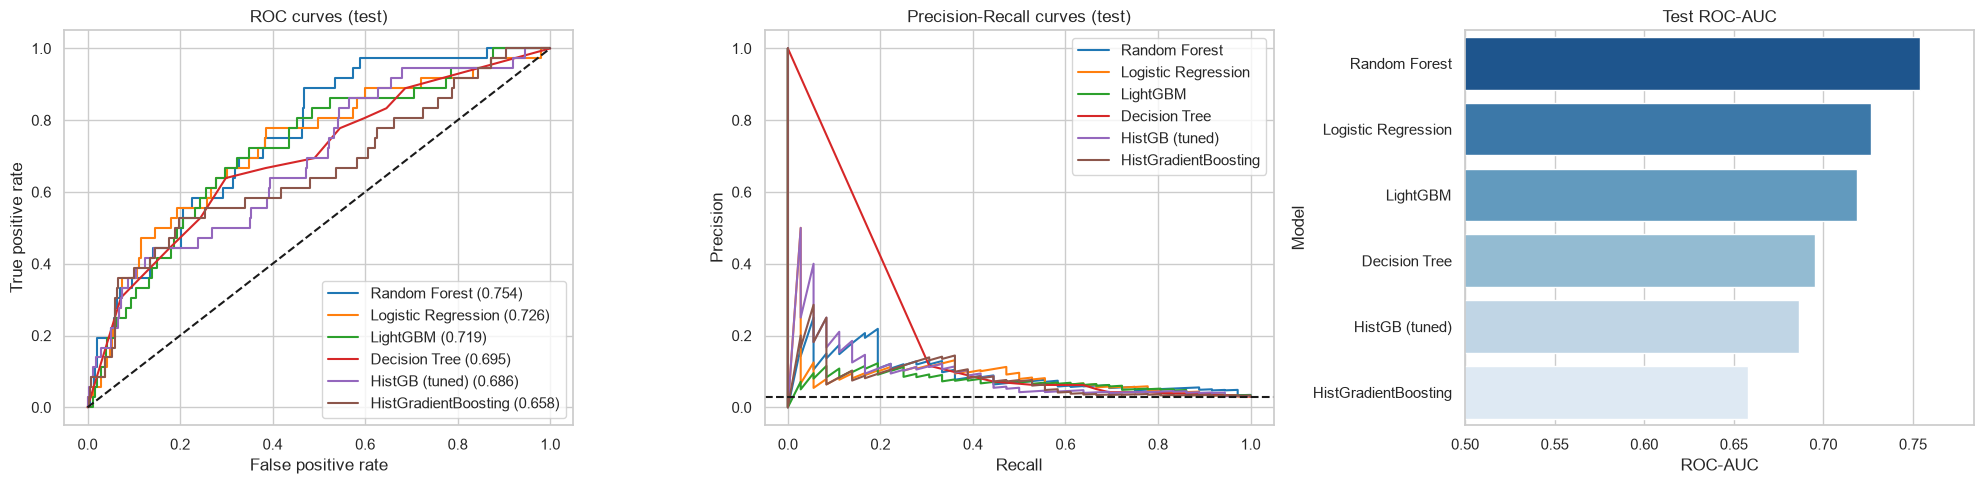

In [76]:
res = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
display(res.round(4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
colors = plt.cm.tab10.colors
for i, name in enumerate(res['Model']):
    fpr, tpr, _ = roc_curve(y_test, probs[name]); axes[0].plot(fpr, tpr, color=colors[i], label=f'{name} ({res.loc[i, "ROC-AUC"]:.3f})')
    pr, rc, _ = precision_recall_curve(y_test, probs[name]); axes[1].plot(rc, pr, color=colors[i], label=name)
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC curves (test)'); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].legend(loc='lower right')
axes[1].axhline(y_test.mean(), color='k', ls='--'); axes[1].set_title('Precision-Recall curves (test)'); axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend()
sns.barplot(data=res, y='Model', x='ROC-AUC', ax=axes[2], palette='Blues_r'); axes[2].set_xlim(0.5, res['ROC-AUC'].max() + 0.03); axes[2].set_title('Test ROC-AUC')
plt.tight_layout(); plt.show()

In [77]:
best_name = res.loc[0, 'Model']
best = fitted[best_name]
b = res.iloc[0]
runner = res.iloc[1] if len(res) > 1 else None
lr_auc = res.loc[res['Model'] == 'Logistic Regression', 'ROC-AUC'].iloc[0]

print(f'RECOMMENDED MODEL FOR PRODUCTION: {best_name}')
print(f'  ROC-AUC {b["ROC-AUC"]:.4f} | PR-AUC {b["PR-AUC"]:.4f} | KS {b["KS"]:.4f} | recall {b["Recall"]:.3f} | precision {b["Precision"]:.3f}')
print(f'  +{(b["ROC-AUC"]-lr_auc):.4f} AUC over the logistic-regression baseline ({lr_auc:.4f}).')
if runner is not None:
    print(f'  Runner-up: {runner["Model"]} (AUC {runner["ROC-AUC"]:.4f}, gap {b["ROC-AUC"]-runner["ROC-AUC"]:.4f}).')
gap = abs(b['Val ROC-AUC'] - b['ROC-AUC'])
print(f'  Validation vs test AUC gap: {gap:.4f}  ->  {"stable, no sign of overfitting" if gap < 0.01 else "check for overfitting"}')

RECOMMENDED MODEL FOR PRODUCTION: Random Forest
  ROC-AUC 0.7541 | PR-AUC 0.0971 | KS 0.4207 | recall 0.361 | precision 0.082
  +0.0276 AUC over the logistic-regression baseline (0.7265).
  Runner-up: Logistic Regression (AUC 0.7265, gap 0.0276).
  Validation vs test AUC gap: 0.0003  ->  stable, no sign of overfitting


# Factors and customer segments eligible for a loan

###  Which factors drive default? (permutation importance)

* Permutation importance measures how much the test AUC drops when one feature is shuffled. It works on any model and is less biased toward high-cardinality features than built-in importances.

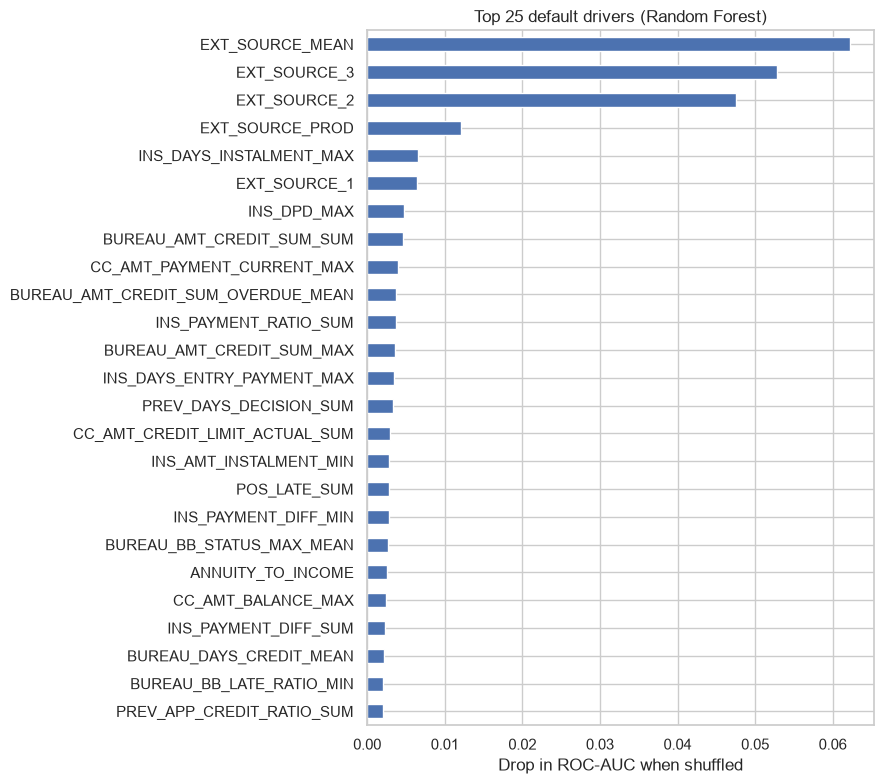

,importance
EXT_SOURCE_MEAN,0.0622
EXT_SOURCE_3,0.0528
EXT_SOURCE_2,0.0476
EXT_SOURCE_PROD,0.0121
INS_DAYS_INSTALMENT_MAX,0.0066
EXT_SOURCE_1,0.0064
INS_DPD_MAX,0.0048
BUREAU_AMT_CREDIT_SUM_SUM,0.0046
CC_AMT_PAYMENT_CURRENT_MAX,0.0040
BUREAU_AMT_CREDIT_SUM_OVERDUE_MEAN,0.0037


In [78]:
from sklearn.inspection import permutation_importance

n_p = min(15_000, len(X_test))
Xp = X_test.sample(n_p, random_state=RANDOM_STATE)
yp = y_test.loc[Xp.index]
pi = permutation_importance(best, Xp, yp, scoring='roc_auc', n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 8))
imp.head(25).sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('Drop in ROC-AUC when shuffled'); ax.set_title(f'Top 25 default drivers ({best_name})')
plt.tight_layout(); plt.show()
display(imp.head(15).to_frame('importance').round(5))

### Risk bands, decile lift and the approval policy

* We convert the model's probability of default (PD) into four risk bands using score cut-offs fixed on the validation set (so the test results stay honest): A = lowest 40% of scores, B = next 30%, C = next 20%, D = riskiest 10%.

,customers,actual_default_rate,avg_predicted_PD,share_of_customers,lift_vs_average,recommended_action
band,,,,,,
A - Low risk,541,0.0055,0.1666,0.4508,0.1848,Approve (standard terms)
B - Moderate,373,0.0322,0.2415,0.3108,1.0724,Approve (standard / risk-based pricing)
C - Elevated,195,0.0513,0.3282,0.1625,1.7094,Manual review / lower limit
D - High risk,91,0.1209,0.4441,0.0758,4.0293,Decline or require collateral


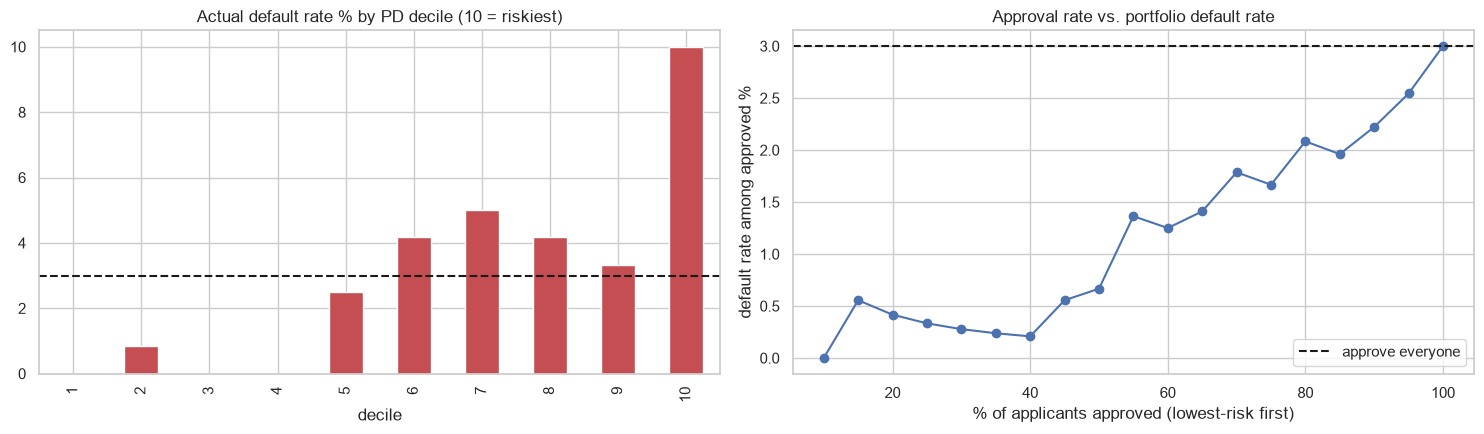

In [79]:
pd_test = probs[best_name]
pd_val = probs[best_name + '__val']
cuts = np.quantile(pd_val, [0.40, 0.70, 0.90])
labels = ['A - Low risk', 'B - Moderate', 'C - Elevated', 'D - High risk']
band = pd.Series(np.digitize(pd_test, cuts), index=X_test.index).map(dict(enumerate(labels)))

base_rate = y_test.mean()
tbl = (pd.DataFrame({'band': band, 'y': y_test, 'pd': pd_test}).groupby('band')
       .agg(customers=('y', 'size'), actual_default_rate=('y', 'mean'), avg_predicted_PD=('pd', 'mean')))
tbl['share_of_customers'] = tbl['customers'] / tbl['customers'].sum()
tbl['lift_vs_average'] = tbl['actual_default_rate'] / base_rate
tbl['recommended_action'] = ['Approve (standard terms)', 'Approve (standard / risk-based pricing)', 'Manual review / lower limit', 'Decline or require collateral']
display(tbl.round(4))

dec = pd.qcut(pd.Series(pd_test, index=X_test.index).rank(method='first'), 10, labels=False) + 1
dtab = pd.DataFrame({'decile': dec, 'y': y_test}).groupby('decile')['y'].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
dtab.plot.bar(ax=axes[0], color='#C44E52'); axes[0].axhline(base_rate*100, color='k', ls='--')
axes[0].set_title('Actual default rate % by PD decile (10 = riskiest)'); axes[0].set_xlabel('decile')

order = np.argsort(pd_test); ys_sorted = y_test.values[order]
rates = np.linspace(0.1, 1.0, 19)
dr = [ys_sorted[:int(len(ys_sorted)*r)].mean()*100 for r in rates]
axes[1].plot(rates*100, dr, marker='o', color='#4C72B0'); axes[1].axhline(base_rate*100, color='k', ls='--', label='approve everyone')
axes[1].set_xlabel('% of applicants approved (lowest-risk first)'); axes[1].set_ylabel('default rate among approved %')
axes[1].set_title('Approval rate vs. portfolio default rate'); axes[1].legend()
plt.tight_layout(); plt.show()

### Which customer segments are eligible? Segment profiles

In [81]:
seg = app.loc[X_test.index, ['NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS',
                             'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'DAYS_BIRTH', 'AMT_INCOME_TOTAL']].copy()
seg['PD'] = pd_test; seg['TARGET'] = y_test.values; seg['BAND'] = band.values
seg['AGE_BAND'] = pd.cut(-seg['DAYS_BIRTH'] / 365.25, [0, 30, 40, 50, 60, 120], labels=['<30', '30-40', '40-50', '50-60', '60+'])
seg['INCOME_BAND'] = pd.qcut(seg['AMT_INCOME_TOTAL'], 4, labels=['Q1 (low)', 'Q2', 'Q3', 'Q4 (high)'])
seg['ELIGIBLE'] = seg['BAND'].isin(labels[:2])

def seg_table(col, min_n=200):
    t = seg.groupby(col, observed=True).agg(customers=('TARGET', 'size'), actual_default_rate=('TARGET', 'mean'),
                                            avg_predicted_PD=('PD', 'mean'), pct_eligible_AB=('ELIGIBLE', 'mean'))
    return t[t['customers'] >= min_n].sort_values('actual_default_rate')

for c in ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'AGE_BAND', 'INCOME_BAND', 'NAME_CONTRACT_TYPE']:
    print(f'\n=== {c} ===')
    display(seg_table(c).round(4))


=== NAME_INCOME_TYPE ===


,customers,actual_default_rate,avg_predicted_PD,pct_eligible_AB
NAME_INCOME_TYPE,,,,
Working,326,0.0153,0.2364,0.7730
State servant,301,0.0233,0.2387,0.7508
Pensioner,273,0.0293,0.2363,0.7729
Commercial associate,300,0.0533,0.2373,0.7500



=== NAME_EDUCATION_TYPE ===


,customers,actual_default_rate,avg_predicted_PD,pct_eligible_AB
NAME_EDUCATION_TYPE,,,,
Lower secondary,412,0.0243,0.2371,0.7670
Secondary,387,0.0284,0.2360,0.7726
Higher education,401,0.0374,0.2384,0.7456



=== AGE_BAND ===


,customers,actual_default_rate,avg_predicted_PD,pct_eligible_AB
AGE_BAND,,,,
30-40,251,0.0199,0.2264,0.7888
40-50,256,0.0273,0.2430,0.7227
60+,212,0.0283,0.2415,0.7689
<30,244,0.0369,0.2230,0.7869
50-60,237,0.0380,0.2530,0.7426



=== INCOME_BAND ===


,customers,actual_default_rate,avg_predicted_PD,pct_eligible_AB
INCOME_BAND,,,,
Q3,300,0.0167,0.2279,0.8000
Q1 (low),300,0.0300,0.2506,0.7000
Q2,300,0.0300,0.2269,0.8000
Q4 (high),300,0.0433,0.2433,0.7467



=== NAME_CONTRACT_TYPE ===


,customers,actual_default_rate,avg_predicted_PD,pct_eligible_AB
NAME_CONTRACT_TYPE,,,,
Revolving loans,630,0.0270,0.2340,0.7698
Cash loans,570,0.0333,0.2407,0.7526


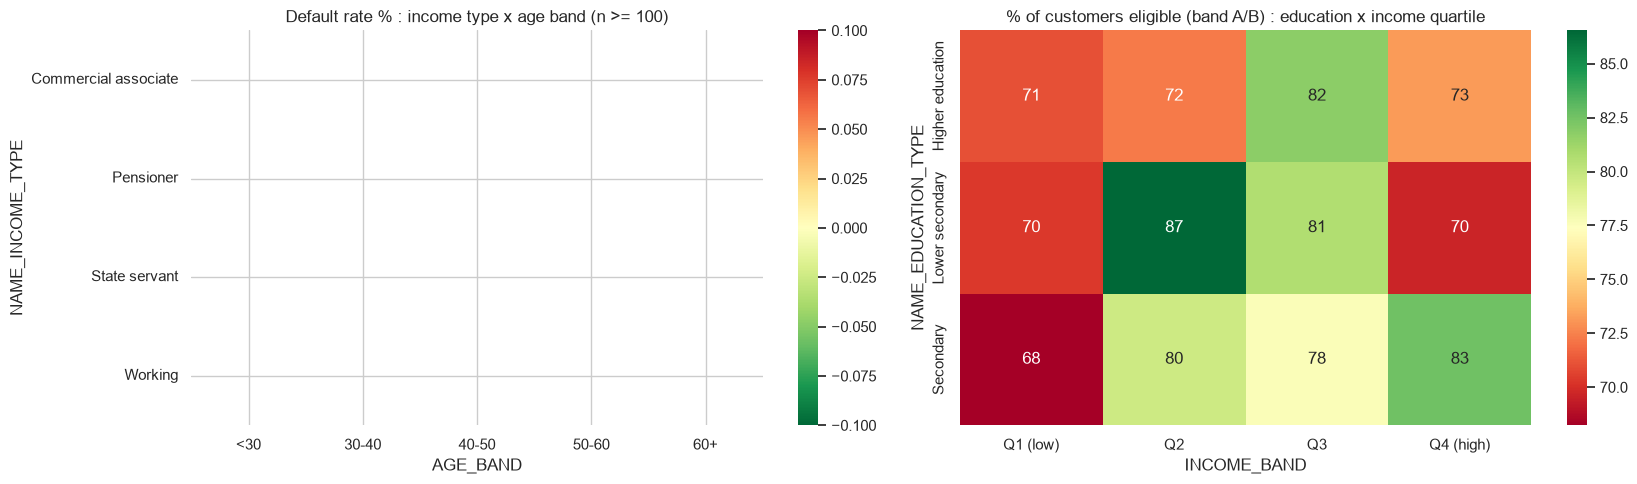

In [82]:
piv = seg.pivot_table(index='NAME_INCOME_TYPE', columns='AGE_BAND', values='TARGET', aggfunc='mean', observed=True) * 100
cnt = seg.pivot_table(index='NAME_INCOME_TYPE', columns='AGE_BAND', values='TARGET', aggfunc='size', observed=True)
piv = piv.where(cnt >= 100)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.heatmap(piv, annot=True, fmt='.1f', cmap='RdYlGn_r', ax=axes[0]); axes[0].set_title('Default rate % : income type x age band (n >= 100)')
sns.heatmap(seg.pivot_table(index='NAME_EDUCATION_TYPE', columns='INCOME_BAND', values='ELIGIBLE', aggfunc='mean', observed=True) * 100,
            annot=True, fmt='.0f', cmap='RdYlGn', ax=axes[1]); axes[1].set_title('% of customers eligible (band A/B) : education x income quartile')
plt.tight_layout(); plt.show()

### Simple, explainable eligibility rules (shallow decision tree on the top drivers)

In [83]:
from sklearn.tree import export_text

top_feats = imp.head(15).index.tolist()
Xr = X_fit[top_feats]
rule_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=1000, class_weight='balanced', random_state=RANDOM_STATE)
rule_tree.fit(Xr.fillna(Xr.median()), y_fit)
print(export_text(rule_tree, feature_names=top_feats, show_weights=True))

|--- EXT_SOURCE_MEAN <= 0.39
|   |--- weights: [545.85, 1268.87] class: 1
|--- EXT_SOURCE_MEAN >  0.39
|   |--- EXT_SOURCE_1 <= 0.50
|   |   |--- weights: [604.61, 100.17] class: 0
|   |--- EXT_SOURCE_1 >  0.50
|   |   |--- weights: [769.55, 550.96] class: 0



# Conclusion and saving the model

In [84]:
import joblib
os.makedirs('artifacts', exist_ok=True)
joblib.dump({'model': best, 'features': X.columns.tolist(), 'band_cuts': cuts.tolist(), 'band_labels': labels,
             'model_name': best_name}, 'artifacts/home_loan_default_model.joblib')
res.to_csv('artifacts/model_comparison.csv', index=False)
print('Saved: artifacts/home_loan_default_model.joblib and artifacts/model_comparison.csv')

def score_applicants(df_features):
    """df_features: DataFrame with the same columns as X. Returns PD, risk band and decision."""
    art = joblib.load('artifacts/home_loan_default_model.joblib')
    Z = df_features.reindex(columns=art['features'])
    p = art['model'].predict_proba(Z)[:, 1]
    b = pd.Series(np.digitize(p, art['band_cuts'])).map(dict(enumerate(art['band_labels']))).values
    decision = np.where(np.isin(b, art['band_labels'][:2]), 'Eligible', np.where(b == art['band_labels'][2], 'Review', 'Decline'))
    return pd.DataFrame({'PD': p, 'risk_band': b, 'decision': decision}, index=df_features.index)

display(score_applicants(X_test.head(5)))

Saved: artifacts/home_loan_default_model.joblib and artifacts/model_comparison.csv


,PD,risk_band,decision
3687,0.1697,A - Low risk,Eligible
2801,0.1820,A - Low risk,Eligible
4802,0.2348,B - Moderate,Eligible
1812,0.1832,A - Low risk,Eligible
1184,0.4089,D - High risk,Decline
